# Embedding nets for observations

Note, you can find the original version of this notebook at [docs/tutorials/04_embedding_networks.ipynb](https://github.com/sbi-dev/sbi/blob/main/docs/tutorials/04_embedding_networks.ipynb) in the `sbi` repository.

## Introduction

When engaging in simulation-based inference, the selection of appropriate summary statistics for observations holds significant importance. These statistics serve to succinctly describe the data generated by simulators, often leveraging domain-specific knowledge. However, in certain scenarios, particularly when dealing with highly complex raw data where domain knowledge may be limited or non-existent, it becomes necessary to learn directly from the data the appropriate summary statistics to employ. `sbi` offers functionality to learn summary statistics from simulation outputs with an **embedding neural network**, referred to as `embedding_net`. 

When an embedding network is used, the posterior approximation for a given observation $x_o$ can be denoted as $q_\phi\big(\theta \mid f_\lambda(x_o)\big)$ where $\phi$ are the parameters of the conditional density estimator and $\lambda$ the parameters of the embedding neural network. Note that the simulation outputs pass through the `embedding_net` before reaching the density estimator and that $\phi$ and $\lambda$ are **jointly learned** during training. `sbi` provides pre-configured embedding networks (MLP, CNN, and permutation-invariant networks) or allows to pass custom-written embedding networks.

It is worth noting that only `NPE` and `NRE` methods can use an `embedding_net` to learn summary statistics from simulation outputs. `NLE` does not offer such functionality because the simulation outputs are also the output of the neural density estimator. 

## Main syntax

## Inferring parameters and test on empirical data

In the example that follows, we consider a simple setup where the data points generated by the simulator model are high-dimensional (32x32 grayscale images) and we use a convolutional neural network as summary statistics extractor.

First of all, we import all the packages required for running the tutorial

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from sbi import analysis, utils
from sbi.inference import NPE, simulate_for_sbi
from sbi.utils.user_input_checks import (
    check_sbi_inputs,
    process_prior,
    process_simulator,
)

seed = 0
torch.manual_seed(seed);

c:\Users\s.velut\AppData\Local\anaconda3\envs\sbi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### The Flash-Vep model from jordy

Jordy made a flash vep simulator that can take many parameter as input as the latency and amplitude of the flash, the number of code we want... 
We start  by just taking one code

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import pyntbci
import scipy.io
mat = scipy.io.loadmat('D:/s.velut/Downloads/DSC_2018.00122_448_v3/derivatives/offline/sub-01/sub-01_mat.mat')
subset = scipy.io.loadmat("D:/s.velut/Documents/These/DCC/SBI/subset_20.mat")["subset"]

sns.set_context("paper", font_scale=1.5)
codes = mat['V'].T
codes.shape

(20, 378)

In [4]:
def simulator_model(parameter,code=None,only_template=False):
    fs = 180  # Hertz
    pr = 60  # Hertz
    amplitude = parameter[0]  # microvolts
    width = parameter[1]  # seconds
    latency = parameter[2]  # seconds
    encoding_length = 0.3  # seconds
    n_channels = 1
    snr = 0.08 # parameter[3]
    # code = parameter[4]

    # Generate codes
    # V = pyntbci.stimulus.make_gold_codes()[subset][0]
    V = codes
    # V = pyntbci.stimulus.modulate(V)
    V = np.tile(V,5).repeat(int(fs/pr),axis=1)
    V = np.concatenate([V[:,0:1],np.diff(V)],axis=1)%255
    n_codes, n_samples = V.shape

    # Generate structure matrices
    M = torch.Tensor(pyntbci.utilities.encoding_matrix(V[:, np.newaxis, :], int(encoding_length * fs)))

    # Generate flash-VEP
    time = torch.Tensor(np.arange(0, encoding_length, 1/fs))
    r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)

    # Generate template responses
    # print(r.unsqueeze(1).shape)
    # print(M.transpose(1, 0).reshape((-1, n_codes * n_samples)).shape)
    T = r.matmul(M.transpose(1, 0).reshape((-1, n_codes * n_samples))).reshape(n_codes, n_samples)
    # T /= T.std(axis=1, keepdims=True)  # normalize amplitudes

    noise=0
    sig_avg = torch.mean(T**2,axis=1)
    sig_avg_db = 10 * np.log10(sig_avg)
    # Calculate noise according to [2] then convert to watts
    noise_avg_db = sig_avg_db - 1/snr
    noise_avg = 10 ** (noise_avg_db / 10)
    # Generate an sample of white noise
    mean_noise = 0
    noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)

    # plt.plot(T[0].numpy()+noise)
    # plt.show()
    # print(T.shape)
    if code is None:
        code = np.arange(0,V.shape[0],1)
    if not only_template:
        return T[code]+noise[code]
    else:
        return T[code]

## Choosing an `embedding_net`

The outputs $x$ from the simulator are defined in a 1024 dimensional space (32 x 32 = 1024). To avoid having to setup a conditional neural density estimator to work directly on such high-dimensional vectors, one could use an `embedding_net` that would take the images as input and encode them into smaller vectors.

`sbi` provides pre-configured embedding networks of the following types:

- Fully-connected multi-layer perceptron
- Convolutional neural network (1D and 2D convolutions)
- Permutation-invariant neural network (for trial-based data, see [here](https://sbi.readthedocs.io/en/latest/how_to_guide/08_permutation_invariant_embeddings.html))

In the example considered here, the most appropriate `embedding_net` would be a CNN for two-dimensional images. We can setup it as per:


In [32]:
from sbi.neural_nets.embedding_nets import CNNEmbedding

embedding_net = CNNEmbedding(
    input_shape=(1, 5670),
    in_channels=1,
    out_channels_per_layer=[6,12],
    num_conv_layers=2,
    num_linear_layers=1,
    output_dim=8,
    kernel_size=1,
    pool_kernel_size=3
)

See [here](https://github.com/sbi-dev/sbi/blob/main/sbi/neural_nets/embedding_nets.py) for details on all hyperparametes for each available embedding net in `sbi`

## The inference procedure

With the `embedding_net` defined and instantiated, we can follow the usual workflow of an inference procedure in `sbi`. The `embedding_net` object appears as an input argument when instantiating the neural density estimator with `sbi.neural_nets.posterior_nn`.


In [33]:
# set prior distribution for the parameters
prior = utils.BoxUniform(low=torch.FloatTensor([0.5,0.005,0.050,0.0]), high=torch.FloatTensor([2.0,0.05,0.500,0.5]))

# make a SBI-wrapper on the simulator object for compatibility
prior, num_parameters, prior_returns_numpy = process_prior(prior)
simulator_wrapper = process_simulator(simulator_model, prior, prior_returns_numpy)
check_sbi_inputs(simulator_wrapper, prior)

C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:35: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:41: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:49: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positiona

In [34]:
from sbi.neural_nets import posterior_nn

# instantiate the neural density estimator
neural_posterior = posterior_nn(model="maf", embedding_net=embedding_net)

# setup the inference procedure with NPE
inferer = NPE(prior=prior, density_estimator=neural_posterior)

In [35]:
# run the inference procedure on one round and 10000 simulated data points
num_simulations = 5_000
theta, x = simulate_for_sbi(simulator_wrapper, prior, num_simulations=num_simulations)
x = torch.reshape(x,(-1,x.shape[-1]))
theta = torch.repeat_interleave(theta,20,dim=0)

  0%|          | 0/5000 [00:00<?, ?it/s]

C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:35: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:41: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_22192\1510403502.py:49: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positiona

In [36]:
density_estimator = inferer.append_simulations(theta, x).train(training_batch_size=256,stop_after_epochs=25,max_num_epochs=200)
posterior = inferer.build_posterior(density_estimator)

 Training neural network. Epochs trained: 201

In [37]:
torch.save(posterior,"D:/s.velut/Documents/These/DCC/SBI/posterior_bigger.pkl")
torch.save(inferer,"D:/s.velut/Documents/These/DCC/SBI/inferer_bigger.pkl")

c:\Users\s.velut\AppData\Local\anaconda3\envs\sbi\Lib\site-packages\torch\serialization.py:1096: UserWarning: When the inference object is pickled, the behaviour of the loaded object changes in the following two ways: 1) `.train(..., retrain_from_scratch=True)` is not supported. 2) When the loaded object calls the `.train()` method, it generates a new tensorboard summary writer (instead of appending to the current one).
  pickler.dump(obj)


## Visualizing the results

We now generate 50000 samples of the posterior distribution of $r$ and $\theta$ when observing an input data point $x$ generated from the `simulator model` with $r = 0.70$ and $\theta = \pi/4$.


In [5]:
inferer = torch.load("D:/s.velut/Documents/These/DCC/SBI/inferer_bigger.pkl")
posterior = torch.load("D:/s.velut/Documents/These/DCC/SBI/posterior_bigger.pkl")

C:\Users\s.velut\AppData\Local\Temp\ipykernel_15680\2849488371.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  inferer = torch.load("D:/s.velut/Documents/These/DCC/SBI/i

In [17]:
# generate posterior samples
true_parameter = torch.as_tensor([1, 0.02, 0.2,0.08])
x_observed = simulator_model(true_parameter,code=5)
samples = posterior.set_default_x(x_observed).sample((10000,))

C:\Users\s.velut\AppData\Local\Temp\ipykernel_15680\1510403502.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_15680\1510403502.py:35: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_15680\1510403502.py:41: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_15680\1510403502.py:49: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positiona

Drawing 10000 posterior samples: 10401it [00:00, 85269.44it/s]            


The figure below shows the statistics of the generated samples.


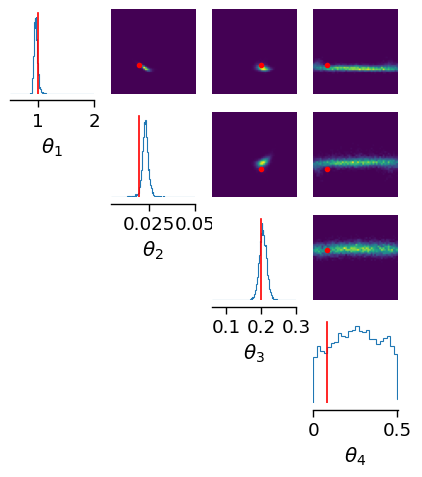

In [18]:
# create the figure
fig, ax = analysis.pairplot(
    samples,
    points=true_parameter,
    labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$", r"$\theta_5$"],
    limits=[[0.5, 2.0], [0.005, 0.05], [0.06, 0.3], [0.0,0.5],[0,62]],
    fig_kwargs=dict(
        points_colors="r",
        points_offdiag={"markersize": 6},
    ),
    figsize=(5, 5),
)

In [13]:
torch.mean(samples,axis=0)-true_parameter

tensor([ 0.0025,  0.0015, -0.0083, -0.0080])

## Assessing the predictive performance of the posterior

Congrats, you have just performed Bayesian inference with the `sbi` toolbox!

But, how do we know that the posterior is correct? The `sbi` toolbox implements a wide range
of methods that diagnose potential issues (more detail [here](https://sbi.readthedocs.io/en/latest/how_to_guide/14_choose_diagnostic_tool.html)). For this tutorial,
we will show only a brief heuristic check: We check whether posterior samples, when simulated,
match the observed data. Such tests are called _Posterior Predictive Checks (PPC)_. Let's
simulate posterior samples:

In [14]:
# theta_posterior = posterior.sample((5000,), x=x_obs)  # Sample from posterior.

x_predictive = [simulator_model(s) for s in samples] # Simulate data from posterior.

C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:46: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally)

And we can check whether posterior samples roughly match the observation:

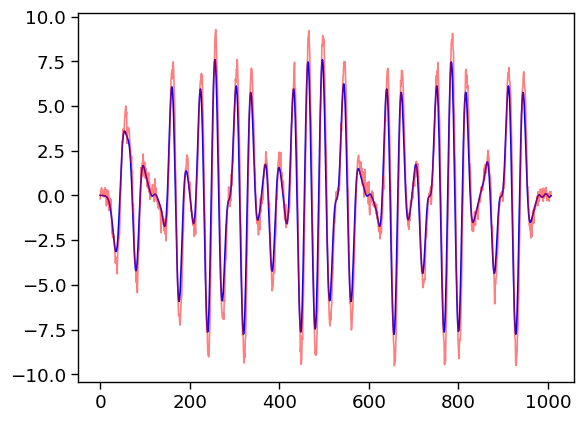

In [ ]:
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)), axis=0).numpy(),color=("blue"))
plt.plot(x_observed.numpy(),color=("red"),alpha=0.5)

In [ ]:
torch.load("D:/s.velut/Documents/These/DCC/SBI/data/FalshVEP/theta_true_list.pkl")

C:\Users\s.velut\AppData\Local\Temp\ipykernel_588\3563330821.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load("D:/s.velut/Documents/These/DCC/SBI/data/FalshVEP

tensor([[1.3349, 0.0170, 0.0917, 0.2965],
        [1.3849, 0.0155, 0.2102, 0.0781],
        [0.5265, 0.0140, 0.0707, 0.4087],
        [1.9675, 0.0463, 0.1172, 0.2461],
        [0.8301, 0.0194, 0.2139, 0.4605],
        [1.5090, 0.0302, 0.1556, 0.3555],
        [1.1510, 0.0089, 0.1895, 0.4624],
        [1.7750, 0.0256, 0.1033, 0.1520],
        [1.2235, 0.0184, 0.1260, 0.3929],
        [0.5668, 0.0250, 0.2739, 0.3371],
        [1.1756, 0.0443, 0.1104, 0.2753],
        [1.9894, 0.0280, 0.0687, 0.0626],
        [0.5917, 0.0157, 0.2186, 0.1339],
        [1.2843, 0.0054, 0.1567, 0.3475],
        [1.5653, 0.0464, 0.2353, 0.0629],
        [1.7046, 0.0115, 0.1601, 0.3790],
        [1.8588, 0.0307, 0.2285, 0.3891],
        [1.9891, 0.0443, 0.1357, 0.3283],
        [0.5725, 0.0216, 0.2186, 0.3948],
        [1.7183, 0.0301, 0.1619, 0.4311],
        [1.8168, 0.0191, 0.1970, 0.2072],
        [1.6105, 0.0128, 0.1064, 0.2013],
        [1.8703, 0.0321, 0.2195, 0.3450],
        [1.9615, 0.0166, 0.1731, 0

C:\Users\s.velut\AppData\Local\Temp\ipykernel_588\677416313.py:23: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_588\677416313.py:33: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_588\677416313.py:39: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T[code].shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_588\677416313.py:45: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) i

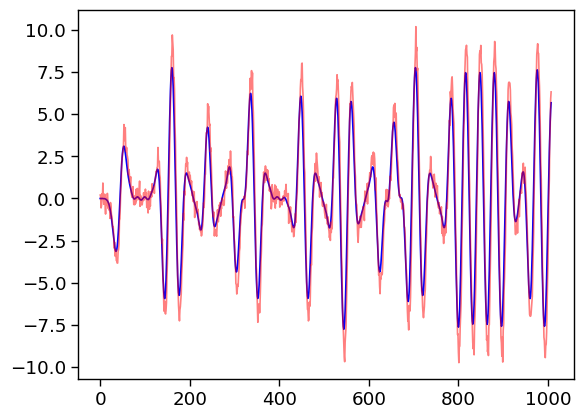

In [ ]:
x_predictive18 = [simulator_model(s,18) for s in samples] # Simulate data from posterior.
x_observed18 = simulator_model(true_parameter,18)
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive18)), axis=0).numpy(),color=("blue"))
plt.plot(x_observed18.numpy(),color=("red"),alpha=0.5)

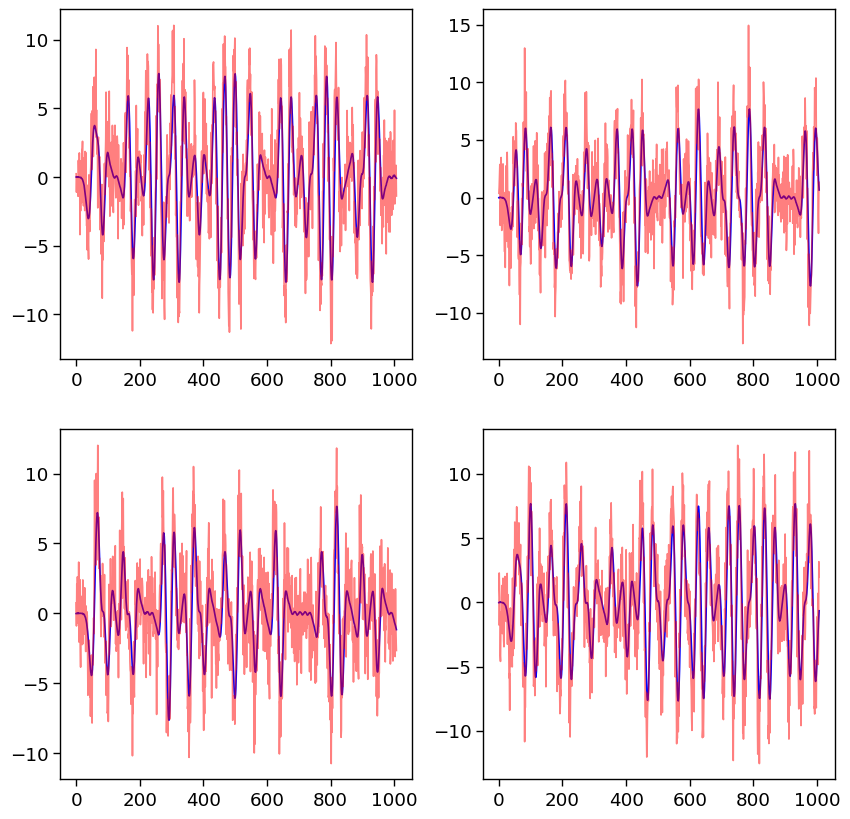

In [ ]:
# print("Posterior predictives: ", torch.mean(torch.Tensor(np.array(x_predictive)), axis=0))
# print("Observation: ", x_observed)
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)[:,0]), axis=0).numpy(),color=("blue"))
plt.plot(x_observed[0].numpy(),color=("red"),alpha=0.5)
plt.subplot(2,2,2)
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)[:,5]), axis=0).numpy(),color=("blue"))
plt.plot(x_observed[5].numpy(),color=("red"),alpha=0.5)
plt.subplot(2,2,3)
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)[:,15]), axis=0).numpy(),color=("blue"))
plt.plot(x_observed[15].numpy(),color=("red"),alpha=0.5)
plt.subplot(2,2,4)
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)[:,28]), axis=0).numpy(),color=("blue"))
plt.plot(x_observed[28].numpy(),color=("red"),alpha=0.5)

## Get empirical data

In [1]:
inferer = torch.load("D:/s.velut/Documents/These/DCC/SBI/inferer2_bigger.pkl")
posterior = torch.load("D:/s.velut/Documents/These/DCC/SBI/posterior2_bigger.pkl")

NameError: name 'torch' is not defined

In [5]:
def correlation(
        A,
        B,
):
    """Compute the correlation coefficient. Computed between two sets of variables.

    Parameters
    ----------
    A: NDArray
        The first set of variables of shape (n_A, n_samples).
    B: NDArray
        The second set of variables of shape (n_B, n_samples).

    Returns
    -------
    scores: NDArray
        The correlation matrix of shape (n_A, n_B).
    """
    if A.ndim == 1:
        A = A[np.newaxis, :]
    if B.ndim == 1:
        B = B[np.newaxis, :]
    assert A.shape[1] == B.shape[1], f"Number of samples in A ({A.shape[1]}) does not equal B ({B.shape[1]})"

    # Demean
    Az = A - np.mean(A, axis=1, keepdims=True)
    Bz = B - np.mean(B, axis=1, keepdims=True)

    # Sum of squares
    ssA = np.sum(Az ** 2, axis=1, keepdims=True)
    ssB = np.sum(Bz ** 2, axis=1, keepdims=True)

    # Correlation coefficient
    outer = np.dot(ssA, ssB.T)
    scores = np.dot(Az, Bz.T) / np.sqrt(outer)

    return scores

In [6]:
import scipy.io
mat1 = scipy.io.loadmat('D:/s.velut/Downloads/DSC_2018.00122_448_v3/derivatives/offline/sub-01/sub-01_mat.mat')
mat2 = scipy.io.loadmat('D:/s.velut/Downloads/DSC_2018.00122_448_v3/derivatives/offline/sub-02/sub-02_mat.mat')

In [57]:
m = mat2["X"][4].T[0]
m2 = mat2["X"][4].T[15]
m3 = mat2["X"][4].T[38]


In [8]:
# generate posterior samples
# true_parameter = torch.as_tensor([1, 0.02, 0.2,0.08])
samples = posterior.set_default_x(m).sample((5000,))
samples2 = posterior.set_default_x(m2).sample((5000,))
samples3 = posterior.set_default_x(m3).sample((5000,))

Drawing 5000 posterior samples:  21%|██        | 1041/5000 [00:02<00:07, 498.82it/s]WARNING:root:Only 0.631% proposal samples are
                    accepted. It may take a long time to collect the remaining
                    3959 samples. Consider interrupting (Ctrl-C) and switching to
                    `build_posterior(..., sample_with='mcmc')`.
Drawing 5000 posterior samples: 5002it [00:09, 505.42it/s]                          
Drawing 5000 posterior samples: 5159it [00:00, 49289.56it/s]            
Drawing 5000 posterior samples: 5274it [00:00, 56733.57it/s]            


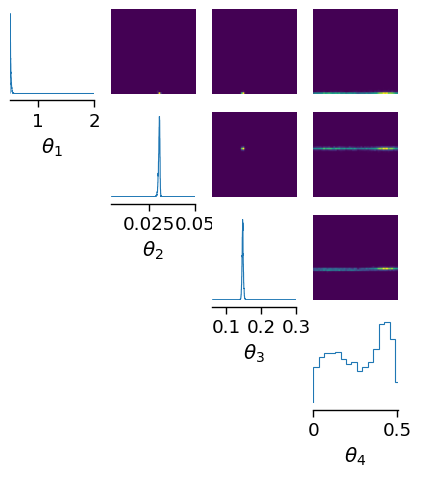

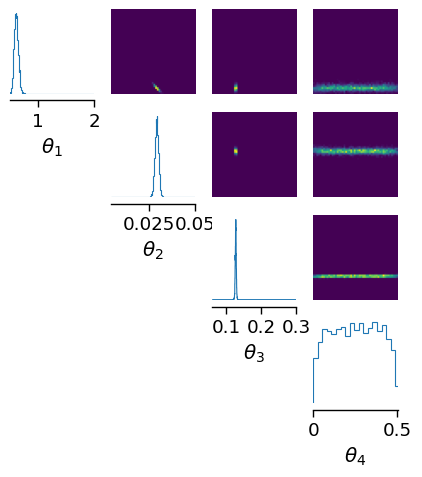

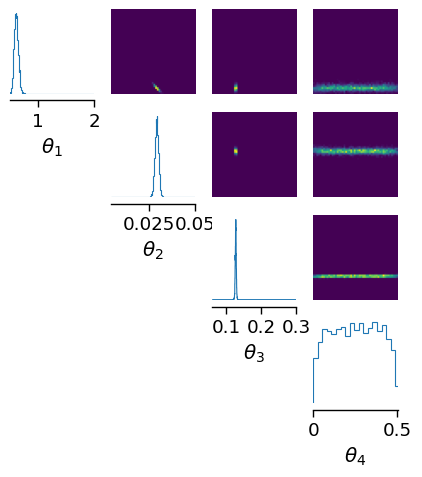

In [9]:
# create the figure
fig, ax = analysis.pairplot(
    samples,
    labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$"],
    limits=[[0.5, 2.0], [0.005, 0.05], [0.06, 0.3], [0.0,0.5]],
    fig_kwargs=dict(
        points_colors="r",
        points_offdiag={"markersize": 6},
    ),
    figsize=(5, 5),
)
# create the figure
fig, ax = analysis.pairplot(
    samples2,
    labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$"],
    limits=[[0.5, 2.0], [0.005, 0.05], [0.06, 0.3], [0.0,0.5]],
    fig_kwargs=dict(
        points_colors="r",
        points_offdiag={"markersize": 6},
    ),
    figsize=(5, 5),
)
fig, ax = analysis.pairplot(
    samples2,
    labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$"],
    limits=[[0.5, 2.0], [0.005, 0.05], [0.06, 0.3], [0.0,0.5]],
    fig_kwargs=dict(
        points_colors="r",
        points_offdiag={"markersize": 6},
    ),
    figsize=(5, 5),
)

In [12]:
mat2['y'].reshape(-1)-1

array([12,  9,  4,  3, 17,  0, 10,  5,  6,  7, 18, 15,  8, 16,  1,  2, 14,
       11, 13, 19,  8, 18,  7, 19,  5, 11,  0, 10, 17, 13, 14,  6,  2,  9,
        1, 16, 15,  4,  3, 12, 19, 11,  5,  6,  7, 17,  8, 12, 14, 18,  3,
        2, 13, 16,  0, 15,  1, 10,  4,  9,  6,  3, 14,  5,  2, 10, 18, 11,
       17, 19, 12,  7, 16,  1,  9,  0, 15,  8, 13,  4,  0, 12, 13,  6,  3,
        4,  2, 14, 17,  5,  1,  8, 15,  7, 11, 16,  9, 10, 19, 18],
      dtype=uint8)

In [2]:
for i in range(20):
    print("get the empirical data")
    xemp = mat2["X"][3].T[i]
    print("get the posterior samples")
    sl = posterior.set_default_x(xemp).sample((1000,)).tolist()
    print("get thetaobs")
    theta_obs = max(sl,key=sl.count)
    print("theta",theta_obs)
    template_pred = [simulator_model(theta_obs,only_template=True,code=j).numpy() for j in range(20)]

    # for i in range(20):
    #     # print(f"template {i+1} avec correlation {np.corrcoef(np.mean(x_pred,axis=0),template_pred[i])[0,1]}")
    #     print(f"template {i+1} avec correlation {np.corrcoef(m2,template_pred[i])[0,1]}")
    ind_max = np.argmax([correlation(xemp,template_pred[j]) for j in range(20)])
    print(f"ind max of empircial data {i} is : {ind_max}  \n ")
    

get the empirical data


NameError: name 'mat2' is not defined

In [24]:
# template_pred = np.array([simulator_model(s,only_template=True) for s in samples])
sl = samples2.tolist()
theta_obs = max(sl,key=sl.count)
template_pred = simulator_model(theta_obs,only_template=True)
# x_pred = np.array([simulator_model(s,only_template=False)[12] for s in sl])

C:\Users\s.velut\AppData\Local\Temp\ipykernel_17364\3444972985.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_17364\3444972985.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_17364\3444972985.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_17364\3444972985.py:46: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positiona

In [200]:
mat2['y'][7]

array([6], dtype=uint8)

In [65]:
# template_pred = np.array([simulator_model(s,only_template=True) for s in samples])
xemp = mat2["X"][4].T[5]
xemp2 = mat2["X"][4].T[12]
sl = posterior.set_default_x(xemp).sample((5000,)).tolist()
theta_obs = max(sl,key=sl.count)
t_a = []

for i in range(20):
    template_pred = simulator_model(theta_obs,only_template=True,code=i).numpy()
    t_a.append(template_pred)
    # print(f"template {i+1} avec correlation {np.corrcoef(np.mean(x_pred,axis=0),template_pred[i])[0,1]}")
    print(f"template {i+1} avec correlation {correlation(xemp,template_pred)}")
ind_max = np.argmax([correlation(m2,t_a[i]) for i in range(20)])
print(np.argmax([correlation(xemp,t_a[i]) for i in range(20)])+1)

Drawing 5000 posterior samples: 5225it [00:00, 39725.20it/s]            
C:\Users\s.velut\AppData\Local\Temp\ipykernel_13584\2093548872.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_13584\2093548872.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_13584\2093548872.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)


template 1 avec correlation [[-0.02323568]]
template 2 avec correlation [[-0.01670027]]
template 3 avec correlation [[-0.0196384]]
template 4 avec correlation [[-0.00529768]]
template 5 avec correlation [[-0.03145771]]
template 6 avec correlation [[0.0291887]]
template 7 avec correlation [[0.01518785]]
template 8 avec correlation [[0.02811445]]
template 9 avec correlation [[-0.03938429]]
template 10 avec correlation [[0.05847779]]
template 11 avec correlation [[0.04253692]]
template 12 avec correlation [[-0.00119456]]
template 13 avec correlation [[0.02654655]]
template 14 avec correlation [[-0.02570854]]
template 15 avec correlation [[0.02565342]]
template 16 avec correlation [[-0.02928015]]
template 17 avec correlation [[0.00760787]]
template 18 avec correlation [[-0.06461285]]
template 19 avec correlation [[0.03135563]]
template 20 avec correlation [[0.022553]]
10


C:\Users\s.velut\AppData\Local\Temp\ipykernel_13584\2093548872.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_13584\2093548872.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_13584\2093548872.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)


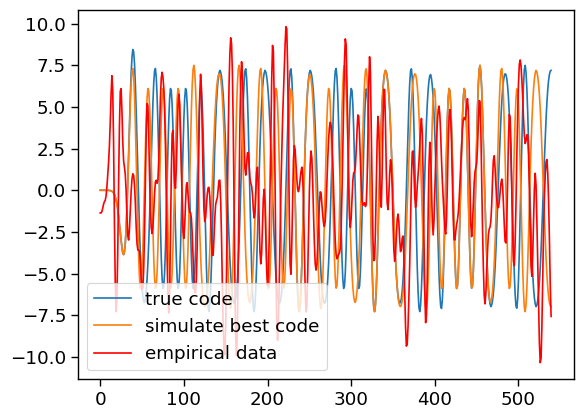

In [66]:
plt.plot(simulator_model(theta_obs,only_template=True,code=0).numpy()[:180*3],label='true code')
plt.plot(simulator_model(theta_obs,only_template=True,code=ind_max).numpy()[:180*3],label='simulate best code')
# plt.plot(m2[:180*3])
plt.plot(xemp[:180*3],color='r',label='empirical data')
plt.legend()

C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_20324\802242972.py:46: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally)

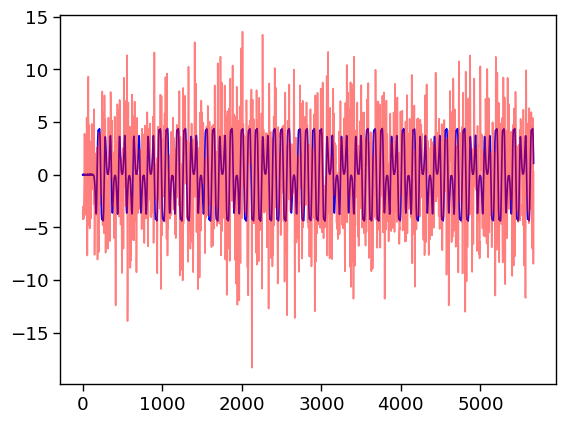

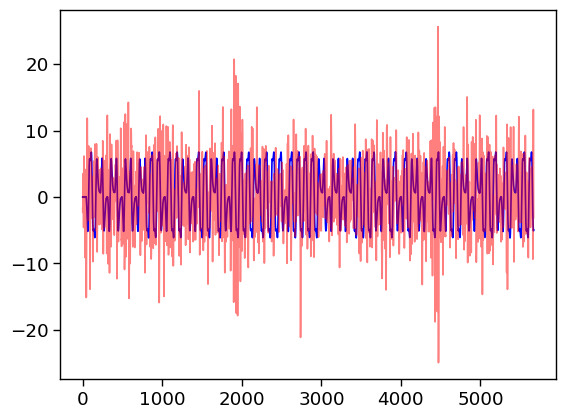

In [29]:
plt.figure(1)
x_predictive = [simulator_model(s)[13] for s in samples] # Simulate data from posterior.
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)), axis=0).numpy(),color=("blue"))
plt.plot(m,color=("red"),alpha=0.5)

plt.figure(2)
x_predictive = [simulator_model(s)[13] for s in samples2] # Simulate data from posterior.
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)), axis=0).numpy(),color=("blue"))
plt.plot(m2,color=("red"),alpha=0.5)

## Connect with RCCA

In [7]:
xemp = mat2["X"][4].T[5]
xemp2 = mat2["X"][4].T[12]
sl = posterior.set_default_x(xemp).sample((1000,)).tolist()

X = np.array([simulator_model(s) for s in sl]).reshape(-1,1,5670)
y = np.tile(np.arange(0,20,1),1000)

Drawing 1000 posterior samples: 1052it [00:00, 24584.26it/s]            
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:48: DeprecationWarning: 

In [8]:
subject = "sub-01" 
tmp = scipy.io.loadmat(f'D:/s.velut/Downloads/DSC_2018.00122_448_v3/derivatives/offline/{subject}/{subject}_mat.mat')
V = tmp["V"].T
fs = int(tmp["fs"])
fr = 60
n_trials, n_channels, n_samples = X.shape
n_classes = V.shape[0]
print("X", X.shape, "(trials x channels x samples)")  # EEG
print("y", y.shape, "(trials)")  # labels
print("V", V.shape, "(classes, samples)")  # codes
print("fs", fs, "Hz")  # sampling frequency
print("fr", fr, "Hz")  # presentation rate

X (20000, 1, 5670) (trials x channels x samples)
y (20000,) (trials)
V (20, 378) (classes, samples)
fs 180 Hz
fr 60 Hz


C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\2189627352.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fs = int(tmp["fs"])


Accuracy: avg=0.08 with std=0.00
ITR: avg=0.2 with std=0.02


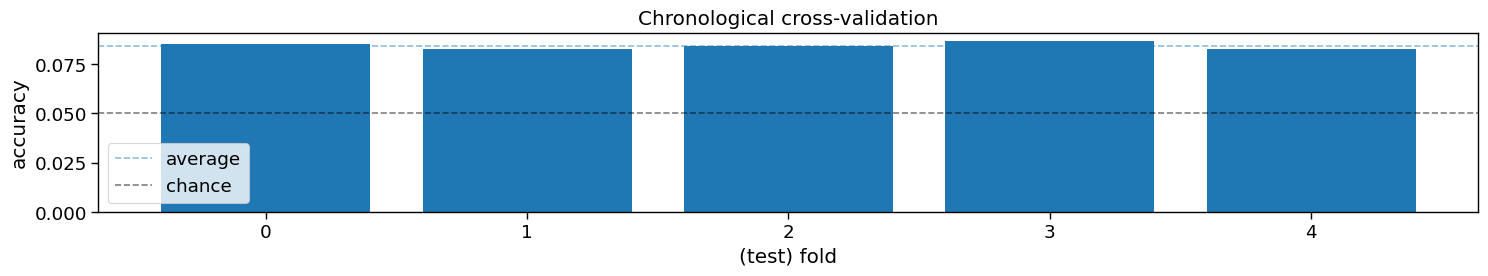

In [9]:
trialtime = 4.2  # limit trials to a certain duration in seconds
intertrialtime = 1.0  # ITI in seconds for computing ITR
n_samples = int(trialtime * fs)

# Chronological cross-validation
n_folds = 5
folds = np.repeat(np.arange(n_folds), int(n_trials / n_folds))
accuracy = np.zeros(n_folds)
for i_fold in range(n_folds):
    # Split data to train and test set
    X_trn, y_trn = X[folds != i_fold, :, :n_samples], y[folds != i_fold]
    X_tst, y_tst = X[folds == i_fold, :, :n_samples], y[folds == i_fold]

    # Train template-matching classifier
    rcca = pyntbci.classifiers.rCCA(stimulus=V, fs=fs, event="duration", encoding_length=0.3, onset_event=True)
    rcca.fit(X_trn, y_trn)

    # Apply template-matching classifier
    yh_tst = rcca.predict(X_tst)

    # Compute accuracy
    accuracy[i_fold] = np.mean(yh_tst == y_tst)

# Compute ITR
itr = pyntbci.utilities.itr(n_classes, accuracy, trialtime + intertrialtime)

# Plot accuracy (over folds)
plt.figure(figsize=(15, 3))
plt.bar(np.arange(n_folds), accuracy)
plt.axhline(accuracy.mean(), linestyle='--', alpha=0.5, label="average")
plt.axhline(1 / n_classes, color="k", linestyle="--", alpha=0.5, label="chance")
plt.xlabel("(test) fold")
plt.ylabel("accuracy")
plt.legend()
plt.title("Chronological cross-validation")
plt.tight_layout()

# Print accuracy (average and standard deviation over folds)
print(f"Accuracy: avg={accuracy.mean():.2f} with std={accuracy.std():.2f}")
print(f"ITR: avg={itr.mean():.1f} with std={itr.std():.2f}")

In [34]:
subject= "sub-02"
tmp = scipy.io.loadmat(f'D:/s.velut/Downloads/DSC_2018.00122_448_v3/derivatives/offline/{subject}/{subject}_mat.mat')
X = tmp["X"].transpose((2, 0, 1))[:,4:5,:]  # transpose to (trials x channels x samples)
y = tmp["y"].reshape(-1) -1   # reshape to (trials)
V = tmp["V"].T

yh = rcca.predict(X)
np.mean(yh == y)

np.float64(0.13)

In [40]:
Xobs = X[5]

sl = posterior.set_default_x(Xobs).sample((1000,)).tolist()

template_obs = np.array([simulator_model(s) for s in sl]).reshape(-1,1,5670)
ya = np.tile(np.arange(0,20,1),1000)
yh = rcca.predict(template_obs)
scores = [np.mean(yh[i::20] == ya[i::20]) for i in range(20)]
np.argmax(scores)

Drawing 1000 posterior samples: 1048it [00:00, 21606.10it/s]            
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  r = amplitude * (1 - ((time - latency) / width)**2) * np.exp(-0.5 * ((time - latency) / width)**2)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:40: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), T.shape)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_24724\1889602374.py:48: DeprecationWarning: 

np.int64(16)

In [48]:
yh[:40]

array([11, 18, 13,  6, 14, 13,  5, 15,  4,  8, 19,  7, 15, 15,  2, 15, 16,
        8, 19,  3, 11, 12, 13,  6, 14, 13,  5, 15,  8, 17, 19,  7, 15, 15,
        2, 13, 16,  8, 19,  3])

In [41]:
scores,y[5]

([np.float64(0.0),
  np.float64(0.066),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.089),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.164),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.022),
  np.float64(0.702),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0)],
 np.uint8(0))